# 02 – Models and evaluation

**Question:** which text representation detects spam best?

| Model | Representation | Idea |
|---|---|---|
| A | TF-IDF on **words** (1–2 grams) | classic baseline: which words appear |
| B | TF-IDF on **character** n-grams (2–5) | robust to spelling tricks ("fr33", "W1N"), typos and other languages |
| C | **Multilingual sentence embeddings** | meaning of the whole message, works across languages |

All three use the same classifier (logistic regression) and are tested on **the same held-out messages**, so the comparison is fair.

In [ ]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import joblib
from sklearn.model_selection import train_test_split, cross_val_score, StratifiedKFold
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import make_pipeline
from sklearn.dummy import DummyClassifier
from sklearn.metrics import (precision_score, recall_score, f1_score, accuracy_score,
                             confusion_matrix, ConfusionMatrixDisplay)

pd.set_option("display.max_colwidth", 140)
ROOT = Path.cwd() if (Path.cwd() / "data").exists() else Path.cwd().parent
(ROOT / "models").mkdir(exist_ok=True)

## 1. Data and train/test split

In [ ]:
df = pd.read_csv("/content/sms_clean.csv")
df["y"] = (df["label"] == "spam").astype(int)          # 1 = spam, 0 = ham

train, test = train_test_split(df, test_size=0.2, stratify=df["y"], random_state=42)
(ROOT / "data").mkdir(exist_ok=True)
train.to_csv(ROOT / "data/train.csv", index=False)
test.to_csv(ROOT / "data/test.csv", index=False)
print(f"train: {len(train)} messages ({train.y.mean():.1%} spam)")
print(f"test:  {len(test)} messages ({test.y.mean():.1%} spam)")

train: 4126 messages (12.5% spam)
test:  1032 messages (12.4% spam)


**Choices to be able to explain:**
- **Stratified** split: train and test keep the same share of spam (~12%).
- `random_state=42`: the split is identical every time, so results are reproducible.
- The split is saved (`train.csv`, `test.csv`) so every notebook uses exactly the same test messages.
- Duplicates were removed in notebook 01 **before** this split, so no test message was seen during training.

## 2. Evaluation function
We look at the **spam** class: *precision* = of the messages flagged as spam, how many really are; *recall* = of all real spam, how many we catch; *F1* = balance of the two.

In [ ]:
results = {}

def evaluate(name, y_true, y_pred):
    results[name] = {
        "accuracy":  accuracy_score(y_true, y_pred),
        "precision": precision_score(y_true, y_pred, zero_division=0),
        "recall":    recall_score(y_true, y_pred),
        "F1":        f1_score(y_true, y_pred),
    }
    return pd.Series(results[name]).round(3)

## 3. Baseline: always answer "ham"
Any real model must beat this.

In [ ]:
dummy = DummyClassifier(strategy="most_frequent").fit(train.text, train.y)
evaluate("Baseline (always ham)", test.y, dummy.predict(test.text))

,0
accuracy,0.876
precision,0.000
recall,0.000
F1,0.000


**Reading:** ~88% accuracy while catching **zero** spam. This is why accuracy is not our main metric.

## 4. Model A – TF-IDF on words + logistic regression

- `ngram_range=(1, 2)`: single words and pairs of words ("call now", "claim your").
- `min_df=2`: ignore words seen in only one message (noise, typos).
- `sublinear_tf=True`: a word repeated 5 times does not count 5 times more.
- `class_weight="balanced"`: errors on spam (the rare class) cost more, so the model does not just ignore it.

In [ ]:
model_a = make_pipeline(
    TfidfVectorizer(ngram_range=(1, 2), min_df=2, sublinear_tf=True),
    LogisticRegression(max_iter=1000, class_weight="balanced"),
)
model_a.fit(train.text, train.y)
evaluate("A – TF-IDF words", test.y, model_a.predict(test.text))

,0
accuracy,0.976
precision,0.876
recall,0.938
F1,0.906


## 5. Model B – TF-IDF on character n-grams + logistic regression

`analyzer="char_wb"` cuts each word into pieces of 2 to 5 characters ("prize" → "pr", "pri", "priz", "rize"...). The model still recognises "pr1ze" or "prizes", and works on any language without a word list.

In [ ]:
model_b = make_pipeline(
    TfidfVectorizer(analyzer="char_wb", ngram_range=(2, 5), min_df=2, sublinear_tf=True),
    LogisticRegression(max_iter=1000, class_weight="balanced"),
)
model_b.fit(train.text, train.y)
evaluate("B – TF-IDF characters", test.y, model_b.predict(test.text))

,0
accuracy,0.990
precision,0.961
recall,0.961
F1,0.961


## 6. Model C – Multilingual sentence embeddings + logistic regression

A pre-trained model (`paraphrase-multilingual-MiniLM-L12-v2`, 50+ languages) turns each message into a vector of 384 numbers that represents its **meaning**. Messages with similar meaning get close vectors, even in different languages. A logistic regression is then trained on these vectors.

*Needs an internet connection the first time (downloads ~470 MB from Hugging Face). Encoding ~5,000 short messages takes about 1–3 minutes on a laptop CPU.*

In [ ]:
EMB_MODEL = "paraphrase-multilingual-MiniLM-L12-v2"
try:
    from sentence_transformers import SentenceTransformer
    encoder = SentenceTransformer(EMB_MODEL)
    X_train_emb = encoder.encode(train.text.tolist(), normalize_embeddings=True, show_progress_bar=True)
    X_test_emb = encoder.encode(test.text.tolist(), normalize_embeddings=True, show_progress_bar=True)
    clf_c = LogisticRegression(max_iter=1000, class_weight="balanced").fit(X_train_emb, train.y)
    joblib.dump(clf_c, ROOT / "models/model_c_embeddings_lr.joblib")
    display(evaluate("C – Multilingual embeddings", test.y, clf_c.predict(X_test_emb)))
except Exception as e:
    clf_c = None
    print("Model C skipped (embedding model not available here):", type(e).__name__, str(e)[:150])

modules.json:   0%|          | 0.00/229 [00:00<?, ?B/s]

config_sentence_transformers.json:   0%|          | 0.00/122 [00:00<?, ?B/s]

README.md:   0%|          | 0.00/3.89k [00:00<?, ?B/s]

sentence_bert_config.json:   0%|          | 0.00/53.0 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/645 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  471MB            

... (6 outputs left out)

config.json:   0%|          | 0.00/190 [00:00<?, ?B/s]

Batches:   0%|          | 0/129 [00:00<?, ?it/s]

Batches:   0%|          | 0/33 [00:00<?, ?it/s]

,0
accuracy,0.974
precision,0.844
recall,0.969
F1,0.902


## 7. Comparison on the test set

In [ ]:
table = pd.DataFrame(results).T.round(3)
table

,accuracy,precision,recall,F1
Baseline (always ham),0.876,0.000,0.000,0.000
A – TF-IDF words,0.976,0.876,0.938,0.906
B – TF-IDF characters,0.990,0.961,0.961,0.961
C – Multilingual embeddings,0.974,0.844,0.969,0.902


### Is the difference real? 5-fold cross-validation on the training set
One test set of ~1,000 messages contains only ~130 spam: a few messages more or less change the score. Cross-validation trains and tests 5 times on different parts of the training data and shows how stable each model is.

In [ ]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
cv_rows = {}
for name, model in [("A – TF-IDF words", model_a), ("B – TF-IDF characters", model_b)]:
    scores = cross_val_score(model, train.text, train.y, cv=cv, scoring="f1")
    cv_rows[name] = {"F1 mean": scores.mean(), "F1 std": scores.std(), "folds": np.round(scores, 3)}
pd.DataFrame(cv_rows).T

,F1 mean,F1 std,folds
A – TF-IDF words,0.928347,0.008421,"[0.934, 0.922, 0.922, 0.942, 0.922]"
B – TF-IDF characters,0.959245,0.006063,"[0.966, 0.956, 0.96, 0.949, 0.966]"


## 8. Confusion matrices
Rows = the truth, columns = the prediction. The two numbers that matter: spam missed (bottom-left) and real messages wrongly flagged (top-right).

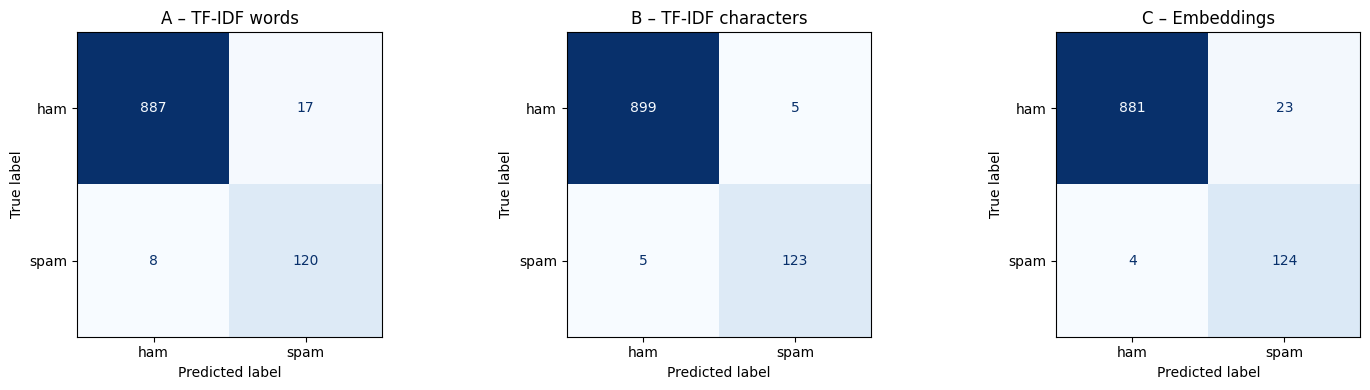

In [ ]:
models_to_plot = [("A – TF-IDF words", model_a.predict(test.text)), ("B – TF-IDF characters", model_b.predict(test.text))]
if clf_c is not None:
    models_to_plot.append(("C – Embeddings", clf_c.predict(X_test_emb)))

fig, axes = plt.subplots(1, len(models_to_plot), figsize=(5 * len(models_to_plot), 4))
for ax, (name, pred) in zip(np.atleast_1d(axes), models_to_plot):
    ConfusionMatrixDisplay(confusion_matrix(test.y, pred), display_labels=["ham", "spam"]).plot(ax=ax, colorbar=False, cmap="Blues")
    ax.set_title(name)
plt.tight_layout(); plt.show()

## 9. Error analysis
What does model B (characters) get wrong, and how sure was it?

In [ ]:
test_err = test.copy()
test_err["p_spam"] = model_b.predict_proba(test.text)[:, 1].round(3)
test_err["pred"] = (test_err.p_spam >= 0.5).astype(int)

missed = test_err[(test_err.y == 1) & (test_err.pred == 0)].sort_values("p_spam")
false_alarms = test_err[(test_err.y == 0) & (test_err.pred == 1)].sort_values("p_spam", ascending=False)
print(f"Spam missed: {len(missed)}   |   Real messages flagged as spam: {len(false_alarms)}")

Spam missed: 5   |   Real messages flagged as spam: 5


### Spam the model missed (false negatives)

In [ ]:
missed[["p_spam", "text"]]

,p_spam,text
4606,0.194,"Hi this is Amy, we will be sending you a free phone number in a couple of days, which will give you an access to all the adult parties..."
3173,0.217,Sorry I missed your call let's talk when you have the time. I'm on 07090201529
4978,0.363,dating:i have had two of these. Only started after i sent a text to talk sport radio last week. Any connection do you think or coincidence?
2326,0.418,Guess who am I?This is the first time I created a web page WWW.ASJESUS.COM read all I wrote. I'm waiting for your opinions. I want to be...
2299,0.419,Babe: U want me dont u baby! Im nasty and have a thing 4 filthyguys. Fancy a rude time with a sexy bitch. How about we go slo n hard! Tx...


### Real messages flagged as spam (false positives)

In [ ]:
false_alarms[["p_spam", "text"]]

,p_spam,text
4410,0.829,I (Career Tel) have added u as a contact on INDYAROCKS.COM to send FREE SMS. To remove from phonebook - sms NO to
1618,0.648,Glad to see your reply.
3517,0.606,"Plz note: if anyone calling from a mobile Co. & asks u to type # or # . Do not do so. Disconnect the call,coz it iz an attempt of 'terro..."
1260,0.595,Your daily text from me – a favour this time
3476,0.567,"Sir, i am waiting for your call, once free please call me."


### What the model relies on (model A, words)
Logistic regression gives each word a weight: positive pushes towards spam, negative towards ham. Looking at them checks that the model learned sensible signals, not artefacts.

In [ ]:
vec, lr = model_a.steps[0][1], model_a.steps[-1][1]
weights = pd.Series(lr.coef_[0], index=vec.get_feature_names_out()).sort_values()
pd.concat({"→ spam": weights.tail(15)[::-1].round(2).reset_index(),
           "→ ham": weights.head(15).round(2).reset_index()}, axis=1)

→ spam       → ham      
     index     0 index     0
0     call  5.80    my -2.53
1      txt  4.35    me -2.37
2     text  3.96    ok -1.83
3     free  3.76  that -1.74
4       to  3.34    it -1.67
5     your  3.22   but -1.52
6       uk  2.97    da -1.46
7   mobile  2.97  then -1.41
8    reply  2.94   how -1.41
9      www  2.93    he -1.33
10    stop  2.92    am -1.32
11   claim  2.87  come -1.32
12    150p  2.81   got -1.22
13    from  2.69   lor -1.22
14     com  2.48    so -1.22

## 10. Conclusions

**Results on the UCI test set (1,032 messages, 128 spam):**
- Both TF-IDF models crush the baseline. **Characters (B) beat words (A):** F1 0.96 vs 0.91 on the test set, and 0.96 vs 0.93 in cross-validation, with low variation across folds, so the gap is not luck.
- Model B makes only 10 errors: 5 spam missed, 5 real messages flagged.

**Error analysis:**
- **Missed spam** looks like a normal message: "Sorry I missed your call… I'm on 07090…" is a premium-rate trap with no spam vocabulary. Content alone cannot catch it; the phone number prefix would.
- **Some "errors" are label mistakes:** "Career Tel has added u… to send FREE SMS. To remove… sms NO" is labelled ham but is clearly spam. The model is right and the label is wrong.
- **False alarms** are short messages with spam-like words ("call", "free", "text").

**What the model learned, and why it is a problem:**
- Spam signals are sensible (*call, txt, free, claim, 150p, www*).
- But the strongest **ham** signals are *my, me, da, lor*: personal pronouns and **Singaporean slang**, because the normal messages come from Singaporean students. The model partly learned "sounds like a Singaporean student = safe". This will not transfer to French or to today's messages.

**→ The 96% here is an upper bound on easy, old data.** Notebook 03 tests the models on recent real scams collected by the team.

## 11. Save the models for the app

In [ ]:
joblib.dump(model_a, ROOT / "models/model_a_tfidf_words.joblib")
joblib.dump(model_b, ROOT / "models/model_b_tfidf_chars.joblib")
table.to_csv(ROOT / "models/results_uci_test.csv")
sorted(p.name for p in (ROOT / "models").iterdir())

['model_a_tfidf_words.joblib',
 'model_b_tfidf_chars.joblib',
 'model_c_embeddings_lr.joblib',
 'results_uci_test.csv']